# 05 ? 2D DWT Transformation

Setiap segmen diubah menjadi matriks 56?56, lalu DWT menghasilkan LL/LH/HL/HH. Keempat subband digabung sebagai **empat kanal dalam satu citra** agar satu contoh pelatihan mewakili satu segmen ECG.


In [1]:
from pathlib import Path
import os, json, pickle, warnings
import numpy as np
import pandas as pd

ROOT = Path("..") if Path("..").exists() else Path(".")
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
WORK_DIR = DATA_DIR / "processed"
WORK_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

CLASS_NAMES = ["CHF", "NSR"]
FS_TARGET = 128
RECORD_LENGTH = 65536
WINDOW_LENGTH = 3136
HOP_LENGTH = 784

import pywt

IN_DIR = WORK_DIR / "04_segments"
OUT_DIR = WORK_DIR / "05_dwt"
OUT_DIR.mkdir(parents=True, exist_ok=True)
SUBBANDS = ["LL", "LH", "HL", "HH"]

In [2]:
Xseg = np.load(IN_DIR / "segments.npy")
meta = pd.read_csv(IN_DIR / "segments_metadata.csv")
if not set(meta["label"]).issubset(set(CLASS_NAMES)):
    raise ValueError(f"Ditemukan label selain CHF/NSR: {sorted(set(meta['label']) - set(CLASS_NAMES))}")

def normalize_minmax(x):
    xmin, xmax = np.min(x), np.max(x)
    if xmax - xmin < 1e-12:
        return np.zeros_like(x, dtype=np.float32)
    return (2.0 * (x - xmin) / (xmax - xmin) - 1.0).astype(np.float32)

images, image_labels, image_records, image_segments = [], [], [], []
for i, seg in enumerate(Xseg):
    z = normalize_minmax(seg).reshape(56, 56)
    ll, (lh, hl, hh) = pywt.dwt2(z, "haar", mode="periodization")
    image = np.stack([ll, lh, hl, hh], axis=-1).astype(np.float32)
    if image.shape != (28, 28, 4):
        raise ValueError(f"Bentuk citra DWT tidak sesuai: {image.shape}")
    images.append(image)
    image_labels.append(meta.iloc[i]["label"])
    image_records.append(meta.iloc[i]["record_id"])
    image_segments.append(int(meta.iloc[i]["segment_id"]))

Ximg = np.stack(images).astype(np.float32)
meta_img = pd.DataFrame({"label": image_labels, "record_id": image_records,
                         "segment_id": image_segments})
np.save(OUT_DIR / "X_images.npy", Ximg)
meta_img.to_csv(OUT_DIR / "images_metadata.csv", index=False)
print("Bentuk citra:", Ximg.shape)  # (jumlah_segmen, 28, 28, 4)
display(meta_img.groupby("label").size().reindex(CLASS_NAMES, fill_value=0).rename("jumlah segmen"))


Bentuk citra: (5280, 28, 28, 4)


label
CHF    2400
NSR    2880
Name: jumlah segmen, dtype: int64

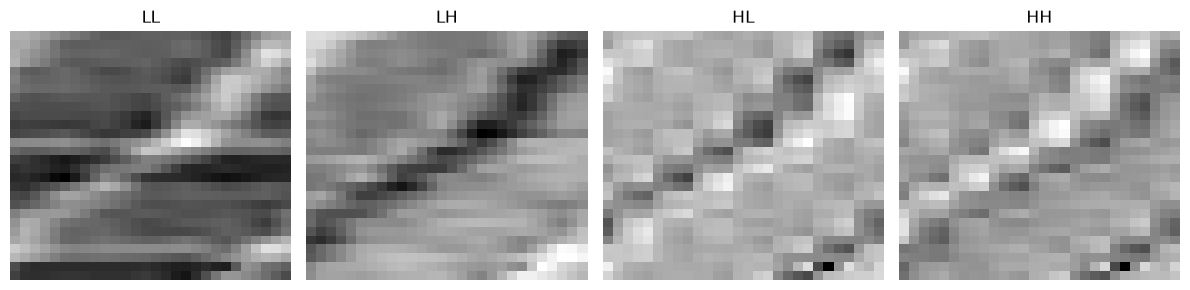

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for channel, (ax, band) in enumerate(zip(axes, SUBBANDS)):
    ax.imshow(Ximg[0, :, :, channel], cmap="gray", aspect="auto")
    ax.set_title(band)
    ax.axis("off")
plt.tight_layout()
plt.show()


Keempat subband DWT menjadi kanal 0?3 dalam satu contoh, sehingga evaluasi dan inferensi menghasilkan satu prediksi per segmen. Pembagian train/validation/test dilakukan berdasarkan `record_id` untuk mencegah kebocoran antar-window dari rekaman yang sama.
